# BÀI TẬP THỰC HÀNH Nhóm 1_4



In [ ]:
import re
import unicodedata
from collections import Counter
from pathlib import Path
import emoji
import matplotlib.pyplot as plt
import pandas as pd
from bs4 import BeautifulSoup
from langdetect import DetectorFactory, detect
from underthesea import word_tokenize
from wordcloud import WordCloud

DetectorFactory.seed = 42  # langdetect cho kết quả ổn định giữa các lần chạy -- xóa sau chạy

BASE_DIR = Path.cwd()
INPUT_FILE = BASE_DIR / "agoda_hue_reviews.txt"

## Mô tả dữ liệu đầu vào

In [8]:
HOTEL_PATTERN = re.compile(
    r"={5,}\s*\nKHÁCH SẠN \d+:\s*(?P<ten>.*?)\s*\n={5,}\s*\n"
    r"Số sao:\s*(?P<sao>[\d,\.]+)\s*\n"
    r"Điểm đánh giá tổng thể:\s*(?P<diem>[\d,\.]+)\s*\n"
    r"(?P<block>.*?)(?=={5,}\s*\nKHÁCH SẠN \d+:|\Z)",
    re.DOTALL,
)

REVIEW_PATTERN = re.compile(
    r"--- Review \d+ ---\s*\n"
    r"Nội dung:\s*(?P<noidung>.*?)\n"
    r"Điểm tổng thể:\s*(?P<diemcn>[\d,\.]+)\s*\n"
    r"Thời điểm review:\s*(?P<thoidiem>.*?)\s*\n"
    r"Quốc tịch:\s*(?P<quoctich>.*?)\s*\n"
    r"(?:Loại phòng:\s*(?P<loaiphong>.*?)\s*\n)?"
    r"(?:Đi theo:\s*(?P<nhomkhach>.*?)\s*\n)?",
    re.DOTALL,
)


def to_float(value: str) -> float:
    return float(value.replace(",", "."))


def parse_agoda_reviews(file_path: Path) -> pd.DataFrame:
    raw_text = file_path.read_text(encoding="utf-8-sig")
    rows = []
    for hotel_match in HOTEL_PATTERN.finditer(raw_text):
        ten_co_so = hotel_match.group("ten").strip()
        so_sao = to_float(hotel_match.group("sao"))
        diem_co_so = to_float(hotel_match.group("diem"))
        for review_match in REVIEW_PATTERN.finditer(hotel_match.group("block")):
            rows.append(
                {
                    "Ten_co_so": ten_co_so,
                    "So_sao": so_sao,
                    "Diem_tong_the_co_so": diem_co_so,
                    "Quoc_tich": review_match.group("quoctich").strip(),
                    "Thoi_diem_review": review_match.group("thoidiem").strip(),
                    "Loai_phong": (review_match.group("loaiphong") or "").strip() or None,
                    "Nhom_khach": (review_match.group("nhomkhach") or "").strip() or None,
                    "Noi_dung_review": review_match.group("noidung").strip(),
                    "Diem_review_ca_nhan": to_float(review_match.group("diemcn")),
                }
            )
    return pd.DataFrame(rows)


df_raw = parse_agoda_reviews(INPUT_FILE)
df_raw.head()


,Ten_co_so,So_sao,Diem_tong_the_co_so,Quoc_tich,Thoi_diem_review,Loai_phong,Nhom_khach,Noi_dung_review,Diem_review_ca_nhan
0,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 13 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Nhóm,"Khách sạn rất đẹp, trang bị phòng ốc đầy đủ, t...",10.0
1,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 10 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Gia đình có em bé,Gia đình tôi đi 2 người lớn 1 trẻ em 8 tuổi. P...,10.0
2,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 08 tháng 6 2026,Suite Gia Đình,Gia đình có em bé,"Phòng rộng rãi, sạch sẽ, nhân viên các bộ phận...",10.0
3,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 27 tháng 9 2025,Suite 2 phòng ngủ trước biển có hồ bơi riêng,Gia đình có trẻ em,Đã trở lại Angsana Lăng Cô!\nTrong chuyến đi n...,10.0
4,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 17 tháng 6 2026,Suite 1 phòng ngủ hướng biển có hồ bơi riêng,Du lịch một mình,Bên cạnh Ban An Tree có một bể bơi lớn hiện ra...,10.0


### Phần 1: Làm sạch dữ liệu bảng & Phân loại ngôn ngữ



#### 1.1. Lọc ngôn ngữ — chỉ giữ review tiếng Việt


In [12]:
def detect_language_safe(text: str) -> str:
    try:
        return detect(text)
    except Exception:
        return "unknown"


df_raw["Ngon_ngu_phat_hien"] = df_raw["Noi_dung_review"].apply(detect_language_safe)
print("Phân bố ngôn ngữ phát hiện được:")
print(df_raw["Ngon_ngu_phat_hien"].value_counts())


Phân bố ngôn ngữ phát hiện được:
Ngon_ngu_phat_hien
vi    49
en     1
Name: count, dtype: int64


In [13]:
df_vi = df_raw[df_raw["Ngon_ngu_phat_hien"] == "vi"].drop(columns=["Ngon_ngu_phat_hien"]).reset_index(drop=True)
print(f"Giữ lại {len(df_vi)}/{len(df_raw)} review tiếng Việt.")


Giữ lại 49/50 review tiếng Việt.


### 1.2. Xử lý missing values cho các cột categorical

In [14]:
missing_before = df_vi[["Loai_phong", "Nhom_khach"]].isna().sum()
print("Số giá trị thiếu trước khi xử lý:")
print(missing_before)

df_vi["Loai_phong"] = df_vi["Loai_phong"].fillna("Không xác định")
df_vi["Nhom_khach"] = df_vi["Nhom_khach"].fillna("Không xác định")

missing_after = df_vi[["Loai_phong", "Nhom_khach"]].isna().sum()
print("\nSố giá trị thiếu sau khi xử lý:")
print(missing_after)

df_vi.head()


Số giá trị thiếu trước khi xử lý:
Loai_phong    0
Nhom_khach    0
dtype: int64

Số giá trị thiếu sau khi xử lý:
Loai_phong    0
Nhom_khach    0
dtype: int64


,Ten_co_so,So_sao,Diem_tong_the_co_so,Quoc_tich,Thoi_diem_review,Loai_phong,Nhom_khach,Noi_dung_review,Diem_review_ca_nhan
0,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 13 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Nhóm,"Khách sạn rất đẹp, trang bị phòng ốc đầy đủ, t...",10.0
1,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 10 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Gia đình có em bé,Gia đình tôi đi 2 người lớn 1 trẻ em 8 tuổi. P...,10.0
2,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 08 tháng 6 2026,Suite Gia Đình,Gia đình có em bé,"Phòng rộng rãi, sạch sẽ, nhân viên các bộ phận...",10.0
3,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 27 tháng 9 2025,Suite 2 phòng ngủ trước biển có hồ bơi riêng,Gia đình có trẻ em,Đã trở lại Angsana Lăng Cô!\nTrong chuyến đi n...,10.0
4,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 17 tháng 6 2026,Suite 1 phòng ngủ hướng biển có hồ bơi riêng,Du lịch một mình,Bên cạnh Ban An Tree có một bể bơi lớn hiện ra...,10.0


## Phần 2: Xây dựng Pipeline tiền xử lý văn bản tiếng Việt 


### 2.1. Từ điển chuẩn hóa (lookup_dict) & từ điển cảm xúc emoji

In [15]:
LOOKUP_DICT = {
    "ks": "khách_sạn",
    "ksan": "khách_sạn",
    "khs": "khách_sạn",
    "nv": "nhân_viên",
    "nt": "nhiệt_tình",
    "bf": "bữa_sáng",
    "buffet": "bữa_sáng",
    "view": "tầm_nhìn",
    "nma": "nhưng_mà",
    "ko": "không",
    "k": "không",
    "hok": "không",
    "dc": "được",
    "đc": "được",
    "mik": "mình",
    "mk": "mình",
    "sp": "sản_phẩm",
    "ib": "nhắn_tin",
    "checkin": "nhận_phòng",
    "check-in": "nhận_phòng",
    "checkout": "trả_phòng",
    "check-out": "trả_phòng",
    "nx": "nhận_xét",
}

POSITIVE_EMOJIS = set("😀😁😂🙂😊😍🥰😄😆👍❤️✨👌🤩😉")
NEGATIVE_EMOJIS = set("😡😠😞😢😭💢👎😤🙁☹️")

# Emoticon gõ bằng ký tự (không phải emoji Unicode)
POSITIVE_EMOTICONS = {":)", ":-)", ":d", ":-d", ";)", ";-)", ":*", "=)"}
NEGATIVE_EMOTICONS = {":(", ":-(", ":'(", "d:"}

NEGATION_WORDS = {"không", "chưa", "chẳng", "đừng", "chả", "chẳng_hề", "chưa_hề"}


### 2.2. Từng bước tiền xử lý

In [16]:
def remove_html_and_urls(text: str) -> str:
    '''Khử nhiễu HTML & URL'''
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text, flags=re.IGNORECASE)
    return text



def to_lowercase(text: str) -> str:
    '''Chuyển chữ thường'''
    return text.lower()


def replace_emojis_and_emoticons(text: str) -> str:
    '''Chuyển đổi Emoji:'''
    for icon in POSITIVE_EMOTICONS:
        text = text.replace(icon, " tuyệt_vời ")
    for icon in NEGATIVE_EMOTICONS:
        text = text.replace(icon, " tồi_tệ ")

    chars = []
    for ch in text:
        if ch in POSITIVE_EMOJIS:
            chars.append(" tuyệt_vời ")
        elif ch in NEGATIVE_EMOJIS:
            chars.append(" tồi_tệ ")
        elif emoji.is_emoji(ch):
            chars.append(" ")  
        else:
            chars.append(ch)
    return "".join(chars)


def expand_lookup_dict(text: str) -> str:
    '''Chuẩn hóa từ viết tắt OTA'''
    text = re.sub(r"(?<=\d)\s*p\b", " phút", text)
    pattern = re.compile(r"(?<!\w)(" + "|".join(re.escape(k) for k in LOOKUP_DICT) + r")(?!\w)")
    return pattern.sub(lambda m: LOOKUP_DICT[m.group(0)], text)


def remove_punctuation_and_numbers(text: str) -> str:
    '''Xóa dấu câu và chữ số'''
    text = re.sub(r"[^\w\sÀ-ỹà-ỹ]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\d+", " ", text)
    return text


def fix_words(text: str) -> str:
    '''Sửa lỗi chính tả'''
    return re.sub(r"(.)\1{2,}", r"\1", text)


def tokenize_vietnamese(text: str) -> list[str]:
    '''Tách từ tiếng Việt'''
    text = re.sub(r"\s+", " ", text).strip()
    if not text:
        return []
    return word_tokenize(text, format="text").split()


def remove_stopwords(tokens: list[str], stopwords: set[str]) -> list[str]:
    '''Loại bỏ Stopwords'''
    return [tok for tok in tokens if tok not in stopwords or tok in NEGATION_WORDS]


In [18]:
def load_vietnamese_stopwords(file_path: Path) -> set[str]:
    '''Đọc danh sách stopwords tiếng Việt, nối cụm nhiều từ bằng '_' để khớp token của underthesea.'''
    if not file_path.exists():
        return set()
    return {
        re.sub(r"\s+", "_", line.strip().lower())
        for line in file_path.read_text(encoding="utf-8-sig").splitlines()
        if line.strip()
    }


STOPWORDS_PATH_CANDIDATES = [
    BASE_DIR / "vietnamese-stopwords.txt",
]
STOPWORDS_PATH = next((p for p in STOPWORDS_PATH_CANDIDATES if p.exists()), None)
VIETNAMESE_STOPWORDS = load_vietnamese_stopwords(STOPWORDS_PATH) if STOPWORDS_PATH else set()
print("Dùng file stopwords:", STOPWORDS_PATH)
print("Số lượng stopwords:", len(VIETNAMESE_STOPWORDS))


Dùng file stopwords: d:\Workspace\KPW\class\1_4\vietnamese-stopwords.txt
Số lượng stopwords: 1942


### 2.3. Hàm pipeline tổng hợp `preprocess_ota_review`

In [19]:
def preprocess_ota_review(text: str, stopwords: set[str] | None = None) -> str:
    
    stopwords = VIETNAMESE_STOPWORDS if stopwords is None else stopwords

    text = remove_html_and_urls(text)
    text = to_lowercase(text)
    text = replace_emojis_and_emoticons(text)
    text = expand_lookup_dict(text)
    text = fix_words(text)
    text = remove_punctuation_and_numbers(text)

    tokens = tokenize_vietnamese(text)
    tokens = remove_stopwords(tokens, stopwords)

    deduped = []
    for tok in tokens:
        if not deduped or deduped[-1] != tok:
            deduped.append(tok)
    return " ".join(deduped)


### 2.4 Mẫu Kiểm thử (Unit Test)

In [20]:
sample_input = (
    "Gia đình mình ở resort Hội An 3 đêm. Ksan view đẹpppp xíu 😍 😁, "
    "nma nv lễ tân checkin chậm mất 30p 😡. Phòng ốc rộng rãi, buffet ngon."
)

sample_output = preprocess_ota_review(sample_input)
print("Đầu vào :", sample_input)
print("Đầu ra  :", sample_output)


Đầu vào : Gia đình mình ở resort Hội An 3 đêm. Ksan view đẹpppp xíu 😍 😁, nma nv lễ tân checkin chậm mất 30p 😡. Phòng ốc rộng rãi, buffet ngon.
Đầu ra  : gia_đình resort hội_an đêm khách_sạn tầm_nhìn đẹp_xíu tuyệt_vời nhân_viên lễ_tân nhận_phòng chậm phút tồi_tệ phòng_ốc rộng_rãi bữa_sáng ngon


### 2.5. Áp dụng pipeline cho toàn bộ dữ liệu

In [21]:
df_vi["Noi_dung_tien_xu_ly"] = df_vi["Noi_dung_review"].apply(preprocess_ota_review)
df_vi = df_vi[df_vi["Noi_dung_tien_xu_ly"].str.len() > 0].reset_index(drop=True)

print(f"Số review sau tiền xử lý (còn nội dung): {len(df_vi)}")
df_vi[["Ten_co_so", "Nhom_khach", "Noi_dung_review", "Noi_dung_tien_xu_ly"]].head()


Số review sau tiền xử lý (còn nội dung): 49


,Ten_co_so,Nhom_khach,Noi_dung_review,Noi_dung_tien_xu_ly
0,Angsana Lang Co,Nhóm,"Khách sạn rất đẹp, trang bị phòng ốc đầy đủ, t...",khách_sạn đẹp trang_bị phòng_ốc đầy_đủ tiện_ng...
1,Angsana Lang Co,Gia đình có em bé,Gia đình tôi đi 2 người lớn 1 trẻ em 8 tuổi. P...,gia_đình đi người_lớn trẻ_em phòng đẹp tầm_nhì...
2,Angsana Lang Co,Gia đình có em bé,"Phòng rộng rãi, sạch sẽ, nhân viên các bộ phận...",phòng rộng_rãi sạch_sẽ nhân_viên bộ_phận thân_...
3,Angsana Lang Co,Gia đình có trẻ em,Đã trở lại Angsana Lăng Cô!\nTrong chuyến đi n...,trở_lại angsana lăng_cô chuyến đi khu nghỉ_dưỡ...
4,Angsana Lang Co,Du lịch một mình,Bên cạnh Ban An Tree có một bể bơi lớn hiện ra...,cạnh ban an_tree bể bơi hiện chỗ khu nghỉ_dưỡn...


## Phần 3: Khám phá dữ liệu văn bản - Text EDA

### 3.1. Thống kê tần suất

In [23]:
all_tokens = " ".join(df_vi["Noi_dung_tien_xu_ly"]).split()
token_freq = Counter(all_tokens)
top20 = token_freq.most_common(20)

for word, count in top20:
    print(f"{word:20s} {count}")


khách_sạn            52
nhân_viên            39
phòng                36
không                28
sạch_sẽ              25
đi                   22
món                  16
thân_thiện           16
huế                  16
đẹp                  15
nhiệt_tình           15
rộng_rãi             15
sông                 13
bơi                  12
trung_tâm            12
bữa                  12
thoải_mái            12
tuyệt_vời            11
ngon                 11
đa_dạng              10


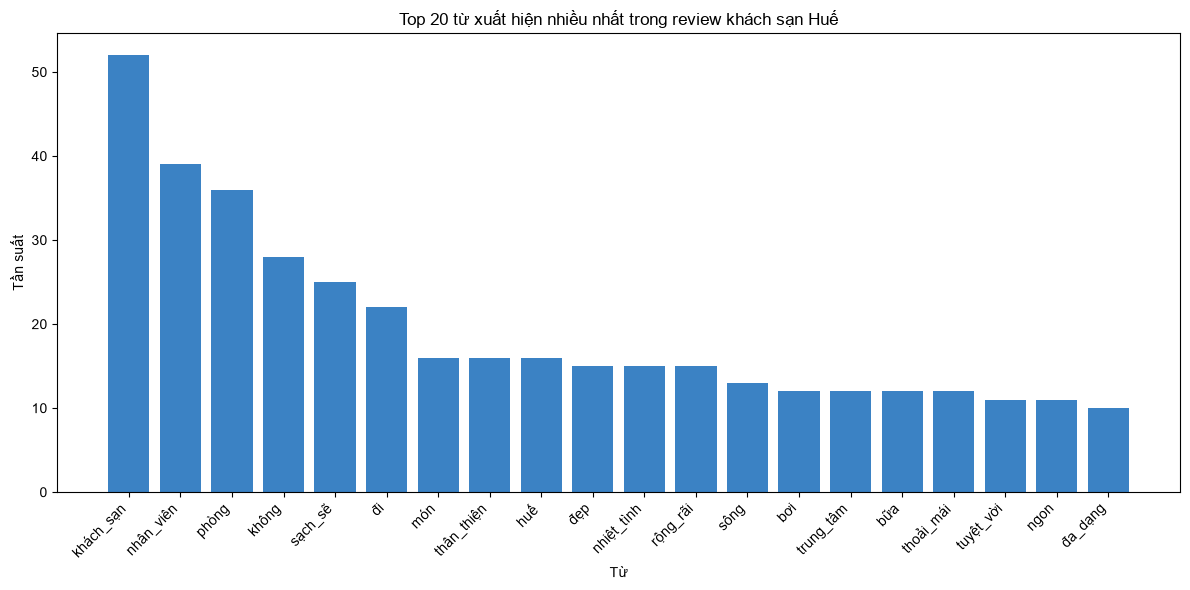

In [24]:
words, counts = zip(*top20)
plt.figure(figsize=(12, 6))
plt.bar(words, counts, color="#3B82C4")
plt.title("Top 20 từ xuất hiện nhiều nhất trong review khách sạn Huế")
plt.xlabel("Từ")
plt.ylabel("Tần suất")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top20_frequency.png", dpi=300)
plt.show()


### 3.2. Đám mây từ (Word Cloud)

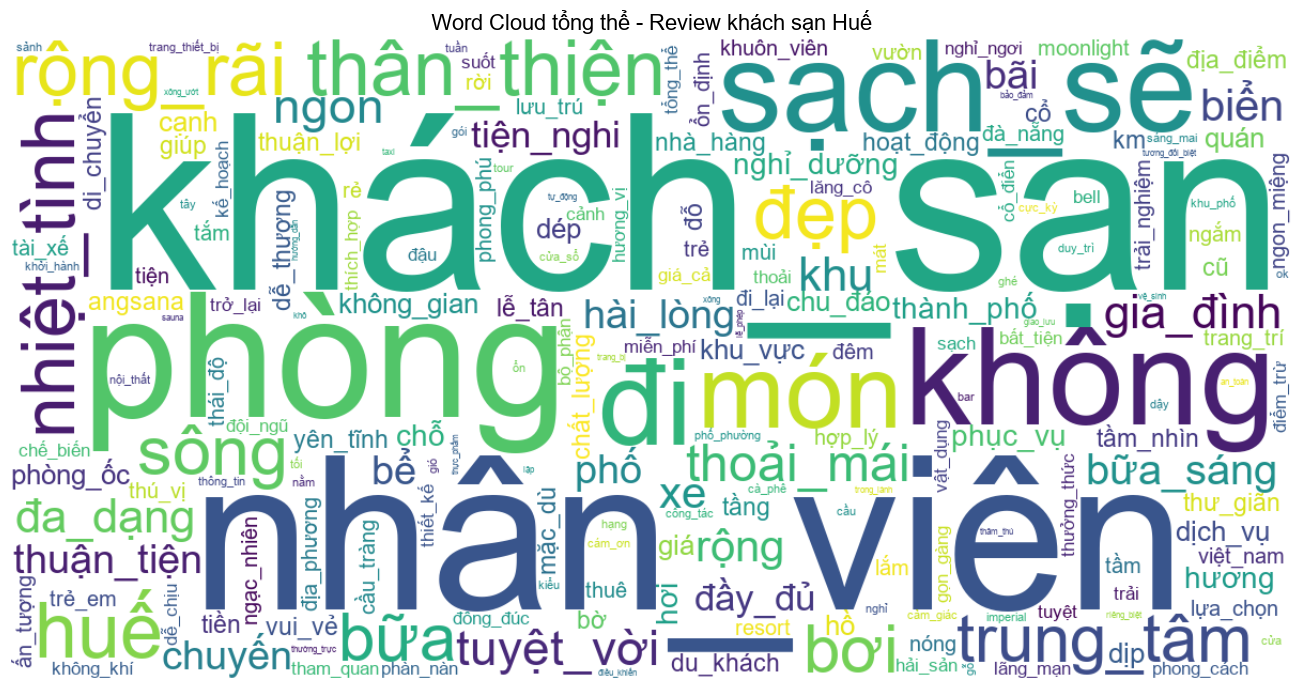

In [28]:


def make_wordcloud(frequencies: dict, title: str, save_name: str) -> None:
    '''Vẽ và lưu word cloud từ một dict {từ: tần suất}.'''
    wc = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        collocations=False,
        font_path=str(FONT_PATH) if FONT_PATH.exists() else None,
    ).generate_from_frequencies(frequencies)
    plt.figure(figsize=(15, 7))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.show()


make_wordcloud(token_freq, "Word Cloud tổng thể - Review khách sạn Huế", "wordcloud_overall.png")


### 3.3. Phân tích so sánh đa chiều (Aspect & Contextual Analysis)

#### a. Theo hạng sao (thay cho so sánh khu vực )
Lý do: File dữ liệu được cung cấp (`agoda_hue_reviews.txt`) chỉ chứa các cơ sở lưu
trú ở Huế, không có cột khu vực. Vì vậy tụi em thay bằng so sánh theo hạng sao (khách sạn cao cấp ≥ 4 sao so với khách sạn phổ thông < 4 sao)

Phan_khuc
Cao cấp (5 sao)           3
Phổ thông (dưới 5 sao)    7
Name: Ten_co_so, dtype: int64


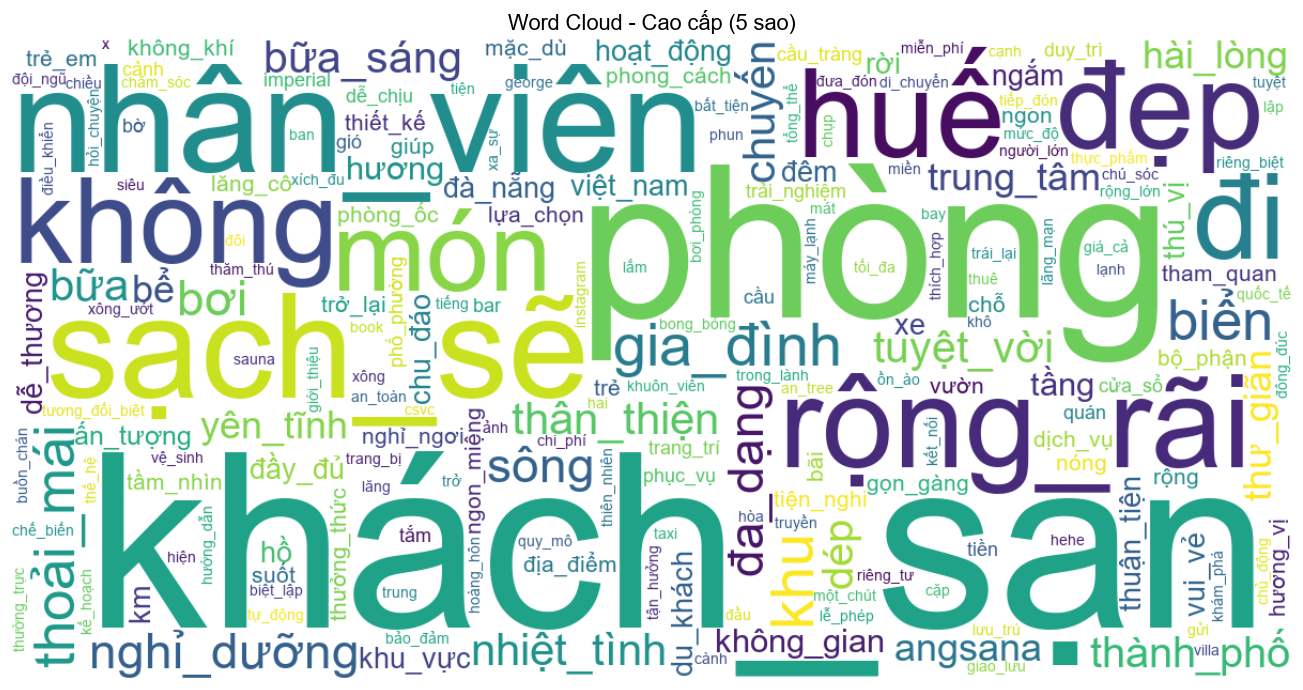

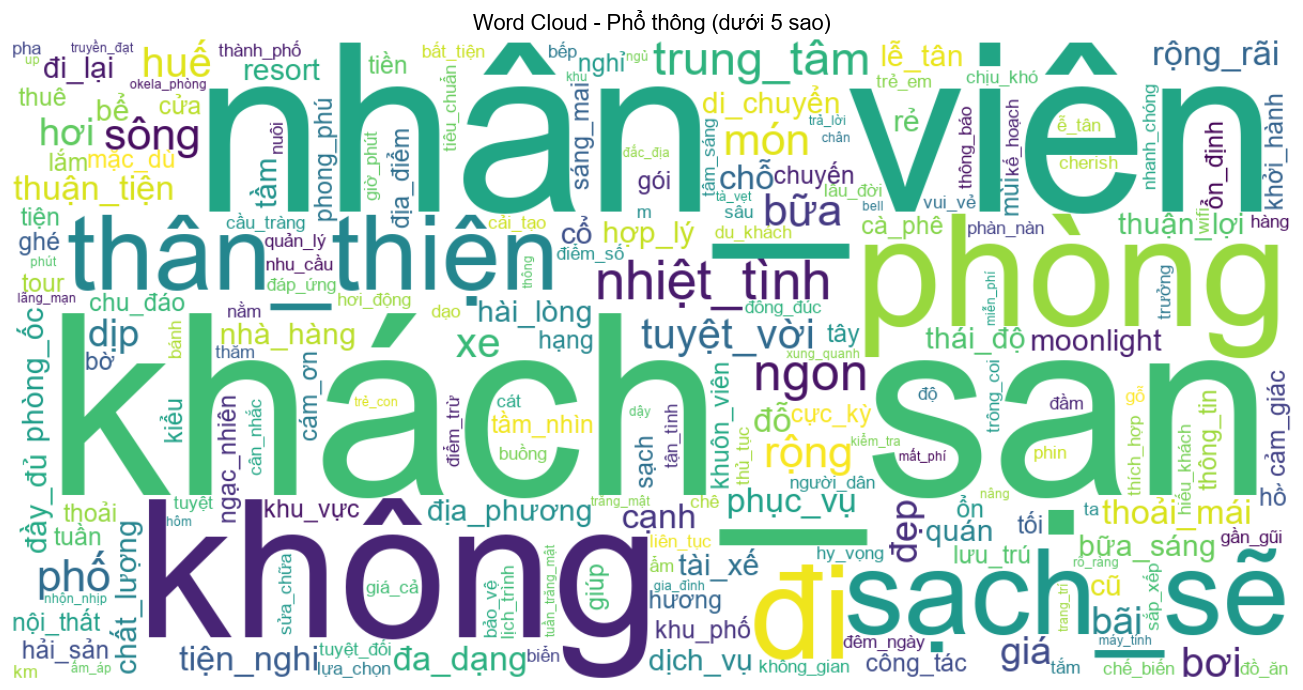

In [36]:
df_vi["Phan_khuc"] = df_vi["So_sao"].apply(lambda s: "Cao cấp (5 sao)" if s >= 5 else "Phổ thông (dưới 5 sao)")
print(df_vi.groupby("Phan_khuc")["Ten_co_so"].nunique())

for segment in df_vi["Phan_khuc"].unique():
    tokens = " ".join(df_vi.loc[df_vi["Phan_khuc"] == segment, "Noi_dung_tien_xu_ly"]).split()
    freq = Counter(tokens)
    safe_name = "cao_cap" if "Cao cấp" in segment else "pho_thong"
    make_wordcloud(freq, f"Word Cloud - {segment}", f"wordcloud_{safe_name}.png")


#### b. Theo nhóm khách: Gia đình vs Cặp đôi

In [37]:
FAMILY_LABELS = {"Gia đình có em bé", "Gia đình có trẻ em"}
COUPLE_LABELS = {"Cặp đôi"}

family_tokens = " ".join(df_vi.loc[df_vi["Nhom_khach"].isin(FAMILY_LABELS), "Noi_dung_tien_xu_ly"]).split()
couple_tokens = " ".join(df_vi.loc[df_vi["Nhom_khach"].isin(COUPLE_LABELS), "Noi_dung_tien_xu_ly"]).split()

family_freq = Counter(family_tokens)
couple_freq = Counter(couple_tokens)

print(f"Số review nhóm Gia đình: {df_vi['Nhom_khach'].isin(FAMILY_LABELS).sum()}")
print(f"Số review nhóm Cặp đôi : {df_vi['Nhom_khach'].isin(COUPLE_LABELS).sum()}")

aspect_words = ["hồ_bơi", "bể_bơi", "trẻ_em", "bữa_sáng", "lãng_mạn", "riêng_tư", "yên_tĩnh", "view", "tầm_nhìn"]
aspect_table = pd.DataFrame(
    {
        "Aspect": aspect_words,
        "Gia_dinh": [family_freq.get(w, 0) for w in aspect_words],
        "Cap_doi": [couple_freq.get(w, 0) for w in aspect_words],
    }
)
aspect_table


Số review nhóm Gia đình: 22
Số review nhóm Cặp đôi : 7


,Aspect,Gia_dinh,Cap_doi
0,hồ_bơi,0,0
1,bể_bơi,0,0
2,trẻ_em,2,0
3,bữa_sáng,4,3
4,lãng_mạn,1,1
5,riêng_tư,1,0
6,yên_tĩnh,3,0
7,view,0,0
8,tầm_nhìn,1,1


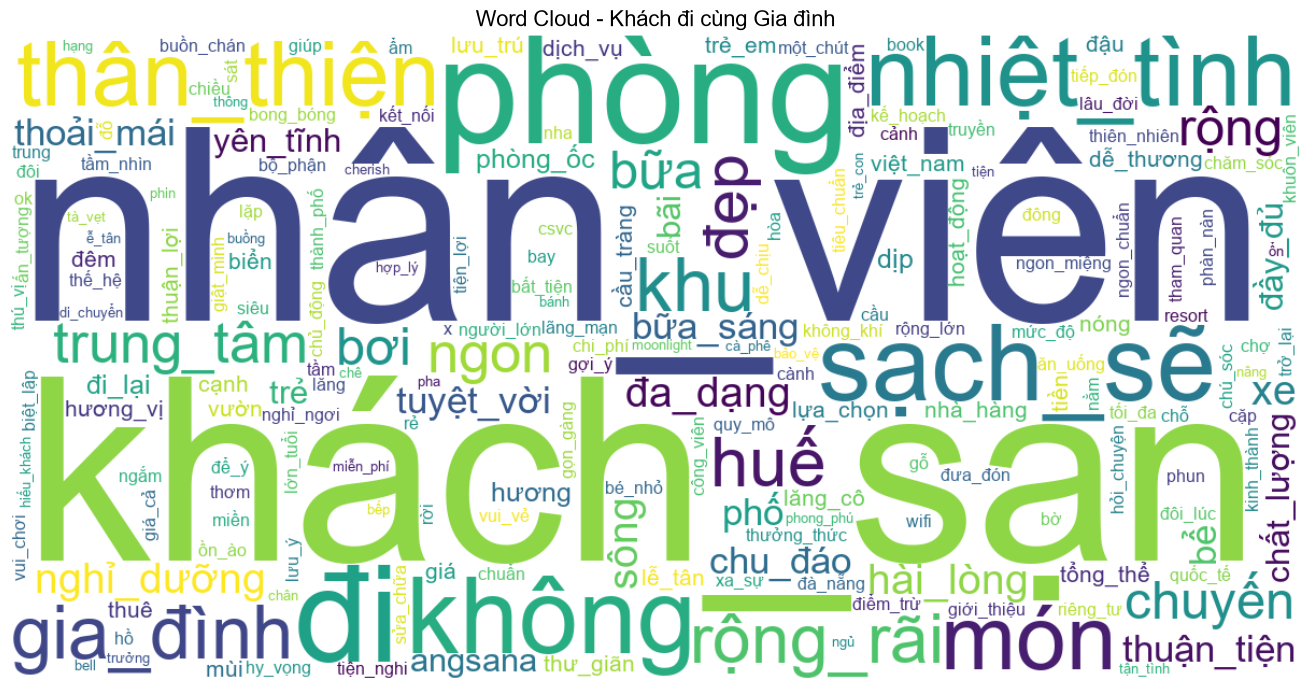

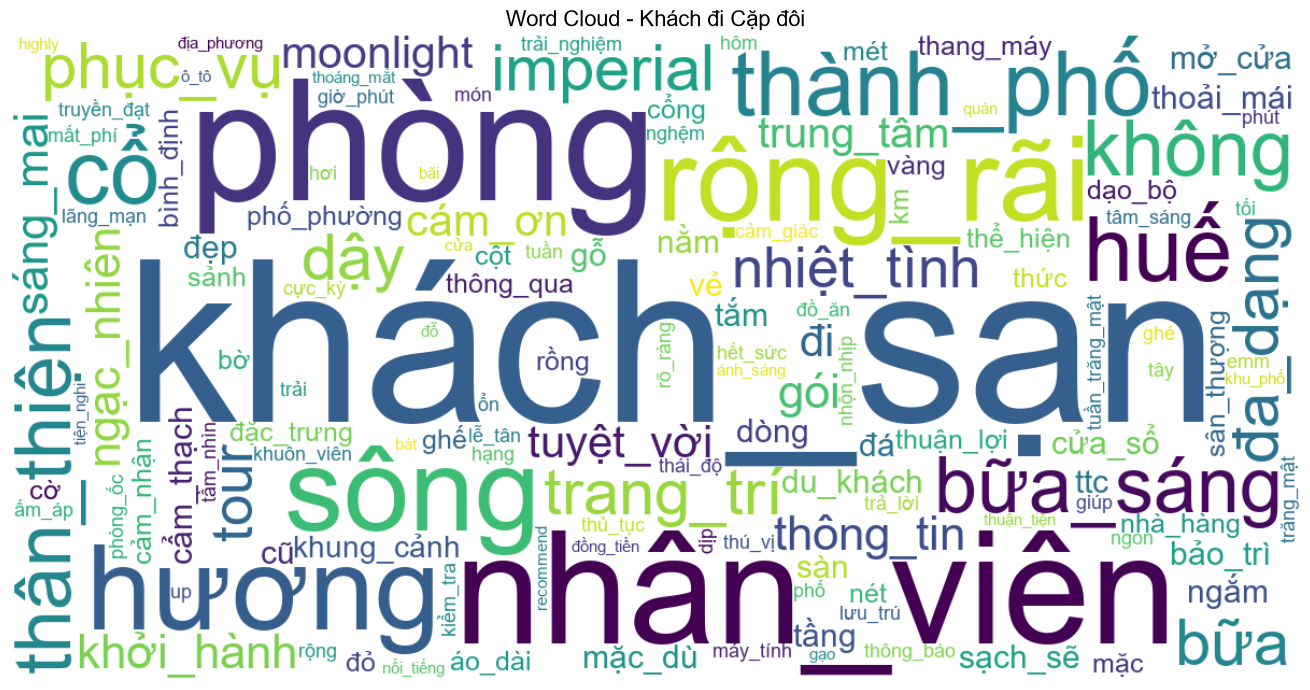

In [38]:
make_wordcloud(family_freq, "Word Cloud - Khách đi cùng Gia đình", "wordcloud_gia_dinh.png")
make_wordcloud(couple_freq, "Word Cloud - Khách đi Cặp đôi", "wordcloud_cap_doi.png")


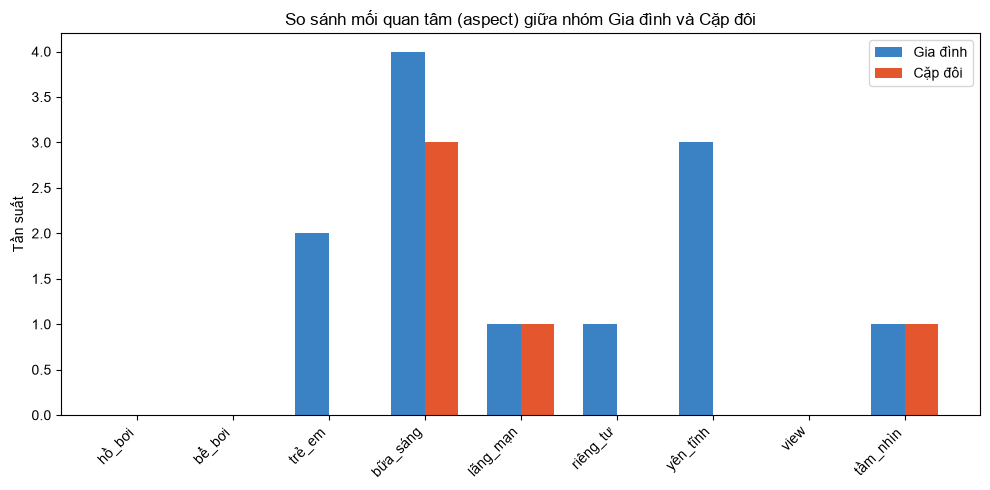

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(aspect_words))
width = 0.35
ax.bar([i - width / 2 for i in x], aspect_table["Gia_dinh"], width, label="Gia đình", color="#3B82C4")
ax.bar([i + width / 2 for i in x], aspect_table["Cap_doi"], width, label="Cặp đôi", color="#E4572E")
ax.set_xticks(list(x))
ax.set_xticklabels(aspect_words, rotation=45, ha="right")
ax.set_ylabel("Tần suất")
ax.set_title("So sánh mối quan tâm (aspect) giữa nhóm Gia đình và Cặp đôi")
ax.legend()
plt.tight_layout()
plt.show()


### 3.4. Phân tích so sánh

- Top từ khóa tần suất cao nhất phản ánh đúng các khía cạnh khách quan tâm nhất khi đánh giá khách sạn Huế:
  vị trí, nhân viên, bữa sáng, phòng ốc, sạch sẽ...
- Khách sạn/resort cao cấp (5 sao) có xu hướng được nhắc đến nhiều với các từ liên quan trải nghiệm cao
  cấp (rộng rãi, hồ bơi, bãi biển riêng, thư giãn ), trong khi nhóm phổ thông thiên về các từ liên quan vị trí trung
  tâm, giá cả, tiện lợi di chuyển.
- Nhóm khách Gia đình nhắc đến `bữa_sáng`, `hồ_bơi`/`bể_bơi` với tần suất cao hơn tương đối so với nhóm
  Cặp đôi, phù hợp với kỳ vọng của đề bài dù cỡ mẫu còn nhỏ (50 review) nên chênh lệch chưa thật rõ rệt.
